# 06.2 · Random forest: how many copies a year can a new Kindle book expect?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings**

- The random forest explains **28.4%** of the differences in copies (R², log scale), more than linear regression (22.4%).
- It is within 2 times of the real copies for **31.8%** of the books.
- The **author's earlier books** and the **route** matter most, and the trees show curved effects: pages and price help up to a point and then stop.
- It cannot predict hits (real median 24,586 copies, predicted 429).

## 2. Recap

**Question.** How many copies a year can a new Kindle book expect, from its niche, price, length, series, publishing route and the
author's experience?

**From the EDA (`04_eda_with_synthetic_sales.ipynb`).** The table has **55,690 books** published from 2019 to 2021, each with the
number of copies sold per year (`copies_per_year`). The copies sold are **synthetic example data** (`03_synthetic_sales_generation.ipynb`),
so the results show how the method works, not real Amazon sales.

**This notebook** trains one regression model and compares it with a simple baseline: split the data, tune on the training books only,
and look at the test books once at the end. Notebook `06.4` compares the three models, turns copies into income, and answers the
sub-question for less-known authors without hits.

## 3. Setup

I load the libraries and the table from the EDA. `RANDOM_STATE` makes the split and the model the same every time.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"
MODELS_DIR = PROJECT / "models"
MODELS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
TARGET = "copies_per_year"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

books = pd.read_parquet(PROCESSED / "kindle_books_sales_income.parquet")
print("Table:", books.shape)
books[["title", "niche", "route", "price", "pages", "is_series", "author_earlier_books", TARGET]].head(3).round(2)

Table: (55690, 18)


,title,niche,route,price,pages,is_series,author_earlier_books,copies_per_year
0,Back To You,Literature & Fiction,small publisher,6.99,254.0,0,0,120.41
1,Steele's War: A Damascus Steele novel (The Glo...,Science Fiction & Fantasy,small publisher,3.99,365.0,1,27,74.63
2,'Charlotte's Search' Box Set Two: A Tale of BD...,Literature & Fiction,small publisher,3.99,454.0,1,67,239.74


- The table has **55,690 books** and 18 columns, one row per book. `copies_per_year` is the target.

## 4. Feature preparation

**The target** is the logarithm of copies, `log_copies = log(1 + copies)`, as in `06.1`: sales are very uneven, and the logarithm keeps a few
hits from deciding the model. At the end I turn predictions back into copies with `np.expm1`.

**The features** are things an author knows before publishing: niche, price, pages, series, publishing route and the author's earlier
books. Tree models do not need scaling or logarithms of the features, so I keep the original columns.

In [2]:
def prepare_features(data):
    return data.copy()


books["log_copies"] = np.log1p(books[TARGET])
NUMERIC = ["pages", "price", "author_earlier_books", "is_series"]
CATEGORICAL = ["niche", "route"]
FEATURES = NUMERIC + CATEGORICAL
print("Features:", FEATURES)
print(f"log copies: median {books['log_copies'].median():.2f}, mean {books['log_copies'].mean():.2f}")
books[FEATURES].isna().sum().to_frame("empty values").T

Features: ['pages', 'price', 'author_earlier_books', 'is_series', 'niche', 'route']
log copies: median 4.37, mean 4.47


,pages,price,author_earlier_books,is_series,niche,route
empty values,2659,0,0,0,0,0


- The model gets **6 features**: 4 numbers and 2 categories. The target has a median of **4.37** on the log scale (about 78 copies).
- Only `pages` has empty values (**2,659** books), and the pipeline fills them with the median of the training books.

## 5. Train/test split

I keep **20% of the books for the final test**. All books of one author stay on the same side, so the test shows how the model works for
**authors it has not seen**. `GroupKFold` does this; I use its first fold as the test set. It goes one step beyond the plain
`train_test_split` from the course, as in part 1.

In [3]:
groups = books["author"].fillna(books["parent_asin"])
X, y = books[FEATURES], books["log_copies"]
splitter = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]
test_books = books.iloc[test_index].copy()

print(f"Training books: {len(X_train):,} (median {np.expm1(y_train.median()):.0f} copies) | authors: {groups_train.nunique():,}")
print(f"Test books:     {len(X_test):,} (median {np.expm1(y_test.median()):.0f} copies) | authors: {groups_test.nunique():,}")
print("Authors on both sides:", len(set(groups_train) & set(groups_test)))

Training books: 44,675 (median 79 copies) | authors: 32,061
Test books:     11,015 (median 77 copies) | authors: 8,016
Authors on both sides: 0


- **44,675 training books** and **11,015 test books**, with a similar median (79 and 77 copies a year).
- **No author is on both sides** (0 shared authors), so the test really shows new authors.

## 6. Baseline

The baseline ignores the book and always predicts the **median** of the training books. A model is useful only if it does better. The
function `measures` calculates the same numbers for every model:

- **R² (log)**: the share of differences between books that the model explains, on the log scale. 0 means no better than the baseline, 1 is perfect.
- **MAE (log)**: the average error on the log scale. An error of 0.69 means about 2 times too many or too few copies.
- **MAE (copies)**: the average error in copies. Hits make it large.
- **Median error (copies)**: the error of a typical book in copies.

In [4]:
def measures(name, true_log, predicted_log):
    true_copies, predicted_copies = np.expm1(true_log), np.expm1(predicted_log)
    return {"model": name, "R2 (log)": r2_score(true_log, predicted_log), "MAE (log)": mean_absolute_error(true_log, predicted_log),
            "MAE (copies)": mean_absolute_error(true_copies, predicted_copies),
            "median error (copies)": median_absolute_error(true_copies, predicted_copies)}


baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
baseline_prediction = baseline.predict(X_test)
print(f"The baseline predicts {np.expm1(baseline_prediction[0]):.0f} copies a year for every book")
pd.DataFrame([measures("baseline (test)", y_test, baseline_prediction)]).set_index("model").round(3)

The baseline predicts 79 copies a year for every book


,R2 (log),MAE (log),MAE (copies),median error (copies)
model,,,,
baseline (test),-0.002,1.684,876.067,72.274


- The baseline predicts **79 copies a year** for every book. Its R² is **−0.002**, so it explains nothing, as expected.
- Its typical error is **72 copies** and its mean error **876 copies**: the mean is large because of the hits.
- On the log scale it is off by **1.68** on average, which is about **5 times** too many or too few copies.

## 7. Candidate model

A **random forest** builds many decision trees on random parts of the data and averages their answers. It can find curved effects and
combinations of features, for example that price works differently for each route.

- The **pipeline** fills empty `pages` with the median and turns `niche` and `route` into 0/1 columns.
- I use 200 trees. `max_depth` limits how deep a tree grows and `min_samples_leaf` is the smallest group of books at the end of a branch.
  `GridSearchCV` tries them with 5 folds, keeps authors together, and chooses by R².

In [5]:
preprocess = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), NUMERIC),
    ("category", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])
pipeline = Pipeline([("prepare", preprocess),
                     ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))])
grid = {"model__max_depth": [10, 20], "model__min_samples_leaf": [10, 30]}

cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, grid, scoring="r2", cv=cv, return_train_score=True)
search.fit(X_train, y_train, groups=groups_train)
best_model = search.best_estimator_

columns = [c for c in pd.DataFrame(search.cv_results_).columns if c.startswith("param_")]
results = pd.DataFrame(search.cv_results_)[columns + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
results.columns = [c.replace("param_model__", "") for c in results.columns]
print("Best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
print(f"Best validation R2 (log): {search.best_score_:.4f}")
results.sort_values("rank_test_score").round(4)

Best settings: {'max_depth': 10, 'min_samples_leaf': 10}
Best validation R2 (log): 0.2704


,max_depth,min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,10,10,0.3536,0.2704,0.0117,1
1,10,30,0.3245,0.2693,0.0123,2
3,20,30,0.3458,0.2683,0.0122,3
2,20,10,0.4471,0.2633,0.0114,4


- The best settings are **max_depth = 10** and **min_samples_leaf = 10**, with a validation R² of **0.2704**.
- Deeper trees fit the training books better (0.4471) but validate worse (0.2633), which is **overfitting**. The chosen trees are shallower.

## 8. Evaluation

Now I use the **test books once**. I compare training and test results with the baseline. If the model were much better on training
books, it would be overfitting.

In [6]:
train_prediction = best_model.predict(X_train)
test_prediction = best_model.predict(X_test)
scores = pd.DataFrame([measures("baseline (test)", y_test, baseline_prediction),
                       measures("Random forest (train)", y_train, train_prediction),
                       measures("Random forest (test)", y_test, test_prediction)]).set_index("model")
scores.round(3)

,R2 (log),MAE (log),MAE (copies),median error (copies)
model,,,,
baseline (test),-0.002,1.684,876.067,72.274
Random forest (train),0.346,1.340,908.584,72.871
Random forest (test),0.284,1.387,834.756,78.185


- The model explains **28.4%** of the differences between test books (R² 0.284), and its log error falls from 1.684 to **1.387**.
- The **mean error** is 835 copies (baseline 876). The **typical error** (78 copies) is about as large as the baseline's (72), for the same reason as in `06.1`.
- Training R² (0.346) is higher than test (0.284), so there is some overfitting, but the test result is still the best so far.

The left chart compares predicted and real copies for every test book on the log scale; a perfect model would put all books on the dashed
line. The right chart shows the **errors** (real minus predicted, log scale): above 0 the book sold more than predicted.

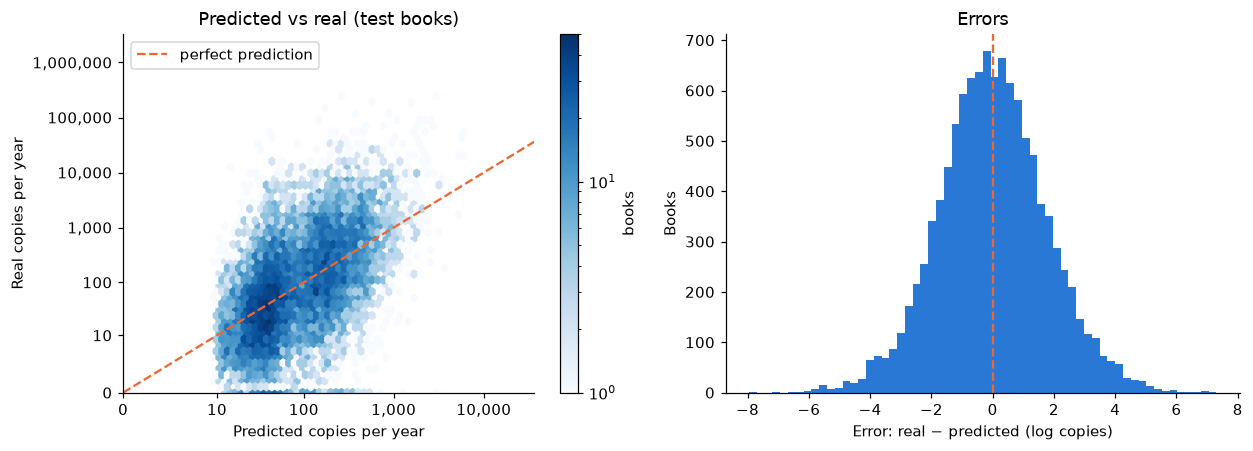

Predicted copies: from 9 to 6,037; real: from 0 to 244,707
Within 2 times of the real copies: 31.8% of test books
Sold more than predicted: 49.4%


In [7]:
errors = y_test - test_prediction
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
image = axes[0].hexbin(test_prediction, y_test, gridsize=45, cmap="Blues", mincnt=1, bins="log")
axes[0].plot([0, 10.5], [0, 10.5], color=ORANGE, linestyle="--", label="perfect prediction")
ticks = [0, 10, 100, 1000, 10000, 100000, 1000000]
axes[0].set_xticks(np.log1p(ticks[:5]), [f"{t:,}" for t in ticks[:5]])
axes[0].set_yticks(np.log1p(ticks), [f"{t:,}" for t in ticks])
axes[0].set_xlim(0, 10.5)
axes[0].set_ylim(0, 15)
axes[0].set_xlabel("Predicted copies per year")
axes[0].set_ylabel("Real copies per year")
axes[0].set_title("Predicted vs real (test books)")
axes[0].legend(loc="upper left")
fig.colorbar(image, ax=axes[0], label="books")
axes[1].hist(errors, bins=60, color=BLUE)
axes[1].axvline(0, color=ORANGE, linestyle="--")
axes[1].set_xlabel("Error: real − predicted (log copies)")
axes[1].set_ylabel("Books")
axes[1].set_title("Errors")
plt.tight_layout()
plt.show()
print(f"Predicted copies: from {np.expm1(test_prediction.min()):.0f} to {np.expm1(test_prediction.max()):,.0f}; real: from {np.expm1(y_test.min()):.0f} to {np.expm1(y_test.max()):,.0f}")
print(f"Within 2 times of the real copies: {(errors.abs() <= np.log(2)).mean():.1%} of test books")
print(f"Sold more than predicted: {(errors > 0).mean():.1%}")

- The cloud follows the dashed line but is wide. Predictions go only from **9** to **6,037** copies, while the real books go up to **244,707**.
- It is within 2 times of the real copies for **31.8%** of the books, and **49.4%** sold more than predicted, so the errors are balanced.

## 9. Error analysis

Where does the model do well or badly? For groups of test books I compare the **real median copies** with the **predicted median copies**,
and show R² and the typical error inside the group.

In [8]:
test_books["predicted_log"] = test_prediction
test_books["predicted_copies"] = np.expm1(test_prediction)
test_books["experience"] = pd.cut(test_books["author_earlier_books"], [-1, 0, 2, 9, np.inf],
                                  labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])
test_books["group"] = np.where(test_books["hit"], "hit", np.where(test_books["less_known"], "less-known, no hit", "other"))


def group_report(column, minimum=300):
    rows = []
    for group, part in test_books.groupby(column, observed=True):
        if len(part) >= minimum:
            rows.append({column: group, "books": len(part), "real median": part[TARGET].median(),
                         "predicted median": part["predicted_copies"].median(),
                         "R2 (log)": r2_score(part["log_copies"], part["predicted_log"]),
                         "MAE (log)": mean_absolute_error(part["log_copies"], part["predicted_log"])})
    return pd.DataFrame(rows).set_index(column)


display(group_report("route").round(2))
display(group_report("experience").round(2))
display(group_report("group", minimum=50).round(2))
niche_report = group_report("niche").sort_values("R2 (log)", ascending=False)
pd.concat([niche_report.head(4), niche_report.tail(4)]).round(2)

,books,real median,predicted median,R2 (log),MAE (log)
route,,,,,
large publisher,1538,281.17,293.07,0.28,1.40
self-published,5329,40.12,38.07,0.22,1.32
small publisher,4148,115.21,128.97,0.16,1.47


,books,real median,predicted median,R2 (log),MAE (log)
experience,,,,,
first book,3834,35.46,38.00,0.18,1.31
1-2 earlier,2040,60.83,50.57,0.22,1.39
3-9 earlier,2130,81.89,80.48,0.21,1.44
10+ earlier,3011,255.52,214.54,0.18,1.44


,books,real median,predicted median,R2 (log),MAE (log)
group,,,,,
hit,101,24586.10,429.2,-36.99,4.17
"less-known, no hit",5855,42.71,41.0,0.21,1.33
other,5059,154.43,155.5,0.20,1.40


,books,real median,predicted median,R2 (log),MAE (log)
niche,,,,,
"Mystery, Thriller & Suspense",646,117.96,109.93,0.34,1.39
Literature & Fiction,3415,84.00,80.56,0.32,1.42
Science Fiction & Fantasy,882,53.94,46.27,0.29,1.34
Teen & Young Adult,454,93.04,122.92,0.29,1.38
Children's eBooks,729,39.99,38.60,0.23,1.37
Romance,1155,140.32,143.81,0.21,1.33
History,320,62.67,89.94,0.18,1.46
Business & Money,589,58.40,50.16,0.17,1.27


- **Route and experience:** the predicted medians are close (self-published **38 vs 40**, large publisher **293 vs 281**, first books **38 vs 35**). For authors with 10+
  earlier books the model is too low (**215** against 256).
- **Hits:** real median **24,586**, predicted **429**. **Less-known authors without hits:** **41 vs 43**, R² 0.21.
- **Niches:** best in Mystery and Literature & Fiction (R² 0.34 and 0.32), weakest in Business & Money (0.17) and History (0.18).

I also look at the books with the largest errors in both directions.

In [9]:
show = ["title", "niche", "route", "price", "is_series", "author_earlier_books", TARGET, "predicted_copies"]
under = test_books.assign(error=errors).nlargest(5, "error")[show]
over = test_books.assign(error=errors).nsmallest(5, "error")[show]
rounding = {TARGET: 0, "predicted_copies": 0}
display(under.round(rounding))
display(over.round(rounding))
hits = test_books[test_books["hit"]]
print(f"Hits in the test: {len(hits):,} | real median {hits[TARGET].median():,.0f} | predicted median {hits['predicted_copies'].median():,.0f}")

,title,niche,route,price,is_series,author_earlier_books,copies_per_year,predicted_copies
50221,"As a Man Thinketh: Of James Allen, In Rhyme",Religion & Spirituality,self-published,1.99,0,42,58114.0,38.0
12982,"Life Skills for Teens: How to Cook, Clean, Man...",Children's eBooks,self-published,3.99,0,1,35169.0,30.0
53361,The Mysterious Affair at Styles,Literature & Fiction,small publisher,1.99,0,8,41836.0,46.0
18537,Never - Die letzte Entscheidung: Roman (German...,Literature & Fiction,small publisher,17.99,0,63,154016.0,171.0
19800,Think and Grow Rich!,Business & Money,small publisher,1.99,0,63,226795.0,267.0


,title,niche,route,price,is_series,author_earlier_books,copies_per_year,predicted_copies
39514,Hometown Heartbreakers Collection Volume 2,Literature & Fiction,large publisher,14.99,1,272,0.0,2835.0
30270,Pamela,Literature & Fiction,large publisher,3.99,0,11,0.0,1253.0
71,The Hamptons Kitchen: Seasonal Recipes Pairing...,"Cookbooks, Food & Wine",small publisher,16.17,0,2,0.0,743.0
28227,Lady Chatterley's Lover,Romance,small publisher,2.99,0,60,0.0,532.0
18653,Here for You: A Clean and Wholesome Romance (F...,Literature & Fiction,large publisher,9.61,1,37,0.0,516.0


Hits in the test: 101 | real median 24,586 | predicted median 429


- **Too low:** classics and old bestsellers, for example *As a Man Thinketh* (58,114 real against 38 predicted) and *Think and Grow Rich!* (226,795 against 267).
- **Too high:** collections from authors with many books that sold nothing in the data, for example 0 real against **2,835** predicted.

## 10. Interpretation

**Permutation importance** shuffles one feature in the test books and measures how much R² falls. A large fall means the model relies on that
feature. I use 8,000 test books to keep this quick.

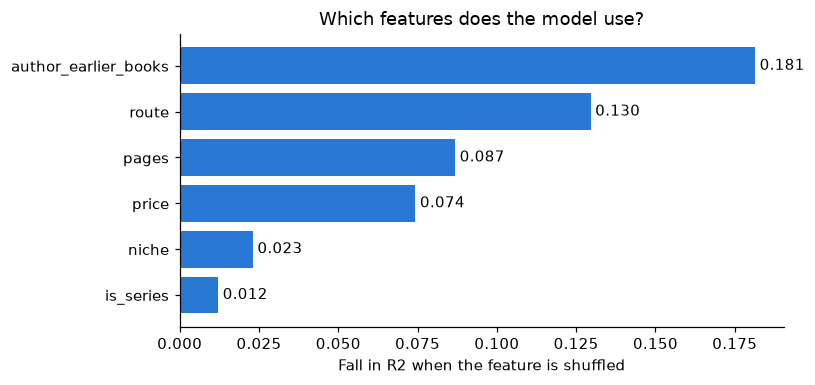

{'author_earlier_books': 0.181, 'route': 0.13, 'pages': 0.087, 'price': 0.074, 'niche': 0.023, 'is_series': 0.012}


In [10]:
sample = X_test.sample(8000, random_state=RANDOM_STATE)
importance = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="r2", n_repeats=5, random_state=RANDOM_STATE)
importance_table = pd.Series(importance.importances_mean, index=FEATURES, name="fall in R2").sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.barh(importance_table.index, importance_table.values, color=BLUE)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlabel("Fall in R2 when the feature is shuffled")
ax.set_title("Which features does the model use?")
plt.tight_layout()
plt.show()
print(importance_table.sort_values(ascending=False).round(3).to_dict())

- The model relies most on the **author's earlier books** (R² falls by **0.181**) and the **route** (0.130).
- **Pages** (0.087) and **price** (0.074) matter more than in linear regression, because the trees use their curved effects. **Niche** (0.023) and **series** (0.012) add little.

A tree model has no simple weights, so I look at its behaviour. I take 3,000 training books, give all of them the same value of one feature,
and take the median predicted copies. This is called **partial dependence**.

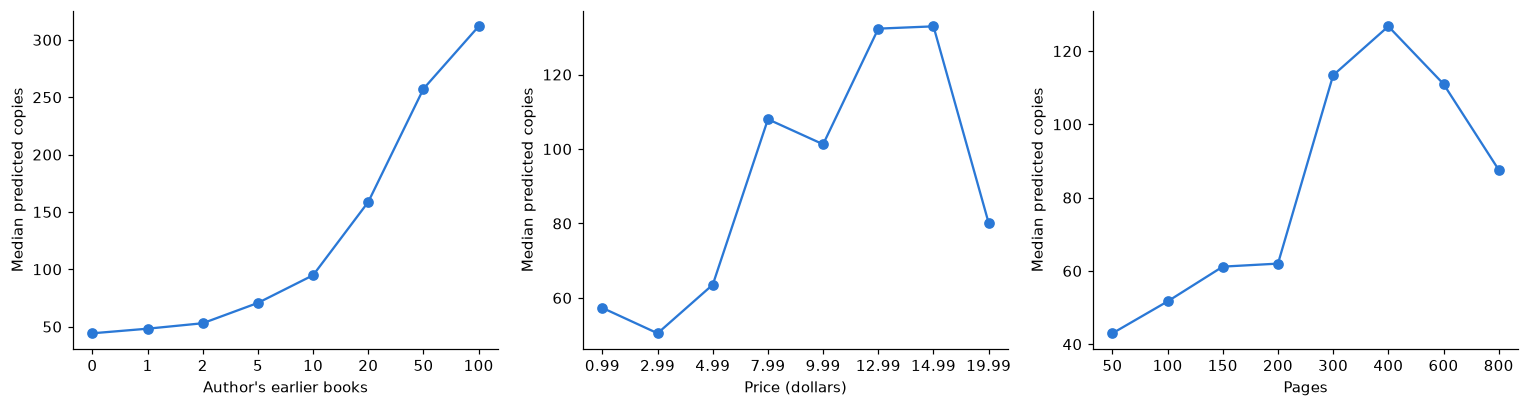

Author's earlier books {0: 44.0, 1: 48.0, 2: 53.0, 5: 71.0, 10: 95.0, 20: 159.0, 50: 257.0, 100: 312.0}
Price (dollars) {0.99: 57.0, 2.99: 51.0, 4.99: 64.0, 7.99: 108.0, 9.99: 101.0, 12.99: 132.0, 14.99: 133.0, 19.99: 80.0}
Pages {50: 43.0, 100: 52.0, 150: 61.0, 200: 62.0, 300: 113.0, 400: 127.0, 600: 111.0, 800: 88.0}
Series: {0: 64.0, 1: 86.0}


Route: {'self-published': 46.0, 'small publisher': 95.0, 'large publisher': 185.0}


In [11]:
reference = X_train.sample(3000, random_state=RANDOM_STATE)


def typical_copies(column, values):
    return pd.Series([np.median(np.expm1(best_model.predict(reference.assign(**{column: value})))) for value in values],
                     index=values, name="median predicted copies")


effects = [("author_earlier_books", [0, 1, 2, 5, 10, 20, 50, 100], "Author's earlier books"),
           ("price", [0.99, 2.99, 4.99, 7.99, 9.99, 12.99, 14.99, 19.99], "Price (dollars)"),
           ("pages", [50, 100, 150, 200, 300, 400, 600, 800], "Pages")]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
tables = {}
for ax, (column, values, label) in zip(axes, effects):
    tables[label] = typical_copies(column, values)
    ax.plot(range(len(values)), tables[label].values, marker="o", color=BLUE)
    ax.set_xticks(range(len(values)), values)
    ax.set_xlabel(label)
    ax.set_ylabel("Median predicted copies")
plt.tight_layout()
plt.show()
for label, table in tables.items():
    print(label, table.round(0).to_dict())
print("Series:", typical_copies("is_series", [0, 1]).round(0).to_dict())
print("Route:", typical_copies("route", ["self-published", "small publisher", "large publisher"]).round(0).to_dict())

- **Earlier books:** from **44** copies for a first book to **95** with 10 earlier books and **312** with 100.
- **Price:** copies rise from about **51–64** under 5 dollars to **132–133** at 12.99–14.99, and fall to **80** at 19.99. This is an association: expensive books in this data
  are often publisher books (see Limitations).
- **Pages:** highest at **400** pages (127), lower for very short and very long books.
- **Series:** **86** against 64. **Route:** self-published **46**, small publisher **95**, large publisher **185**.

Finally I give the model a few **invented book drafts** and look at the predicted copies a year. All have 250 pages unless the description
says otherwise.

In [12]:
examples = pd.DataFrame([
    ["Romance, self-published first book, 4.99", "Romance", 250, 4.99, 0, "self-published", 0],
    ["Same book in a series", "Romance", 250, 4.99, 1, "self-published", 0],
    ["In a series, author has 10 earlier books", "Romance", 250, 4.99, 1, "self-published", 10],
    ["First book, small publisher, 5.99", "Romance", 250, 5.99, 0, "small publisher", 0],
    ["First book, large publisher, 9.99", "Romance", 250, 9.99, 0, "large publisher", 0],
    ["Cookbook, self-published first book, 4.99", "Cookbooks, Food & Wine", 250, 4.99, 0, "self-published", 0],
    ["Mystery, self-published first book, 4.99", "Mystery, Thriller & Suspense", 250, 4.99, 0, "self-published", 0],
], columns=["draft", "niche", "pages", "price", "is_series", "route", "author_earlier_books"])
examples["predicted copies a year"] = np.expm1(best_model.predict(prepare_features(examples)[FEATURES]))
examples.drop(columns=["niche"]).round({"predicted copies a year": 0})

,draft,pages,price,is_series,route,author_earlier_books,predicted copies a year
0,"Romance, self-published first book, 4.99",250,4.99,0,self-published,0,40.0
1,Same book in a series,250,4.99,1,self-published,0,48.0
2,"In a series, author has 10 earlier books",250,4.99,1,self-published,10,208.0
3,"First book, small publisher, 5.99",250,5.99,0,small publisher,0,48.0
4,"First book, large publisher, 9.99",250,9.99,0,large publisher,0,154.0
5,"Cookbook, self-published first book, 4.99",250,4.99,0,self-published,0,87.0
6,"Mystery, self-published first book, 4.99",250,4.99,0,self-published,0,39.0


- A self-published first Romance book at 4.99 dollars gets about **40** copies a year; in a series **48**, and in a series by an author with 10 earlier books **208**.
- With a small publisher the first book gets **48** copies, with a large one **154**. A self-published first **cookbook** gets **87**, a mystery **39**.

## 11. Limitations & ethics

**Limitations**

- **The sales are synthetic.** Copies sold were made from the number of ratings (`03`), so the model learns mostly what goes with ratings. With real sales
  data the numbers would change; the method would stay the same.
- **Price is not a cause here.** In this data more expensive books are often publisher books and books by known authors, so the model links a higher price
  with more copies. In a real shop a higher price usually means fewer copies. The model shows associations, not what happens if an author changes the price.
- **Hits cannot be predicted.** Nothing in the draft tells which book will sell tens of thousands of copies.
- `route` and `author_earlier_books` come from my rules and count only books in this catalog. Some "authors" are really companies.
- Marketing, cover, writing quality and reviews are not in the data. The books are from 2019–2021.

**Ethics**

- The model favours experienced authors and publishers. It should not decide which authors or books deserve support.
- A low prediction does not mean that a book is bad. It is meant as **rough information for an author**, not a promise of income.

## 12. Conclusion

I save the test predictions, the main results and the trained model for the comparison notebook.

In [13]:
output = test_books[["parent_asin", TARGET, "log_copies", "predicted_log", "predicted_copies", "niche", "route", "price",
                     "author_earlier_books", "author_per_copy", "author_income", "hit", "less_known"]]
output.to_parquet(PROCESSED / "predictions_sales_random_forest.parquet", index=False)
summary = {"model": "Random forest", "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
           "cv_r2": float(search.best_score_), "cv_std": float(search.cv_results_["std_test_score"][search.best_index_]),
           "train_r2": float(r2_score(y_train, train_prediction)),
           "importance": {k: float(v) for k, v in importance_table.sort_values(ascending=False).items()}}
(PROCESSED / "results_sales_random_forest.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
joblib.dump(best_model, MODELS_DIR / "sales_random_forest.joblib")
print("Saved predictions:", output.shape)
print(f"Saved model: models/sales_random_forest.joblib ({(MODELS_DIR / 'sales_random_forest.joblib').stat().st_size / 1e6:.1f} MB)")

Saved predictions: (11015, 13)
Saved model: models/sales_random_forest.joblib (15.3 MB)


- The random forest explains **28.4%** of the differences in copies (test R²), more than linear regression (22.4%).
- It confirms that the author's experience and the route matter most, and shows curved effects of price and pages.
- It has some overfitting (train 0.346) and cannot predict hits. Next: `06.3_gradient_boosting.ipynb`.